The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
16 detected / 16 true   F=1.00  P=1.00  R=1.00


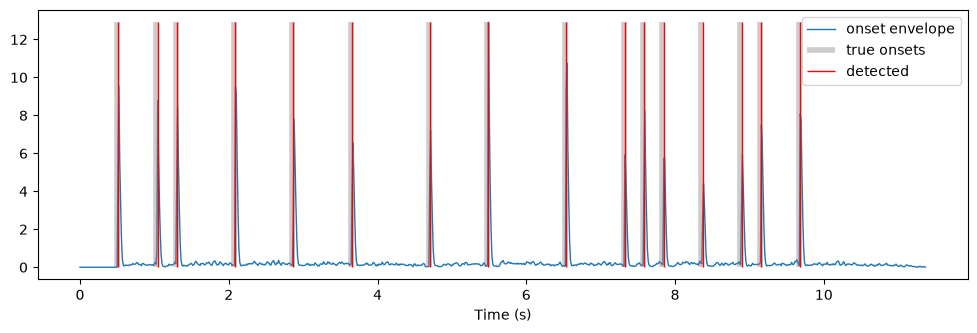

In [4]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import librosa
import pretty_midi
import mir_eval
import matplotlib.pyplot as plt

from pianotrans.load import load_audio
from pianotrans.onsets import onset_envelope, detect_onsets
from pianotrans.config import HOP

name = "melody_000"
y, sr = load_audio(f"../data/test/{name}.wav")
env = onset_envelope(y, sr)
frames = detect_onsets(env, sr)
est = librosa.frames_to_time(frames, sr=sr, hop_length=HOP)
ref = np.array([n.start for n in pretty_midi.PrettyMIDI(f"../data/test/{name}.mid").instruments[0].notes])

F, P, R = mir_eval.onset.f_measure(ref, est, window=0.05)   # hit if within 50 ms
print(f"{len(est)} detected / {len(ref)} true   F={F:.2f}  P={P:.2f}  R={R:.2f}")

t_env = librosa.times_like(env, sr=sr, hop_length=HOP)
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(t_env, env, lw=1, label="onset envelope")
ax.vlines(ref, 0, env.max(), color="grey", lw=4, alpha=0.4, label="true onsets")
ax.vlines(est, 0, env.max(), color="red", lw=1, label="detected")
ax.set_xlabel("Time (s)"); ax.legend(loc="upper right")
fig.savefig(f"../figures/onsets_{name}.png", dpi=150, bbox_inches="tight")

In [5]:
for d in [0.05, 0.1, 0.2, 0.3, 0.5]:
    scores = []
    for wav in sorted(Path("../data/test").glob("*.wav")):
        yy, _ = load_audio(str(wav))
        r = np.array([n.start for n in pretty_midi.PrettyMIDI(str(wav.with_suffix(".mid"))).instruments[0].notes])
        e = librosa.frames_to_time(detect_onsets(onset_envelope(yy, sr), sr, delta=d), sr=sr, hop_length=HOP)
        scores.append(mir_eval.onset.f_measure(r, e, window=0.05)[0])
    print(f"delta={d}: mean F={np.mean(scores):.3f}")

delta=0.05: mean F=1.000
delta=0.1: mean F=1.000
delta=0.2: mean F=0.994
delta=0.3: mean F=0.947
delta=0.5: mean F=0.629
